# Data Preparation

In [1]:
# Reproducibility
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Random seed set to {SEED}")


Random seed set to 42


### Why Data Preparation Matters

Before we dive into model design, we need high-quality data.  
In this project, we aim to generate *synthetic human-like handwriting* to improve CAPTCHA robustness against bots.

Both our **Conditional GAN** and **Conditional Diffusion Model** will need:
- Clean, normalized images of handwritten digits or characters.  
- Corresponding class labels (digits 0–9) to guide the generation process.


## The MNIST Dataset

The [MNIST dataset](http://yann.lecun.com/exdb/mnist/) contains 70,000 grayscale images of handwritten digits (0–9).  
Each image is **28×28 pixels** and belongs to one of 10 classes.

For our project:
- Each digit represents a "class condition" the model should learn to generate.
- We’ll normalize all pixel values to the range `[-1, 1]` — a common practice for GANs and diffusion models.


## 1.0 Import and Setup 

In [2]:
# Import core libraries
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os, sys

from data_utils.dataloader import get_mnist_loaders
from utils.visualize import show_batch

device = (
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f" Running on device: {device}")


 Running on device: cuda


In [3]:
# Load data using helper script 

# Define transformations: ToTensor + normalization
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Scale to [-1, 1]
])

# Load using our helper function
train_loader, test_loader = get_mnist_loaders(batch_size=128, transform=transform)

print(f"Training batches: {len(train_loader)} | Test batches: {len(test_loader)}")



  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  2%|▏         | 197k/9.91M [00:00<00:06, 1.43MB/s]

 10%|▉         | 950k/9.91M [00:00<00:01, 4.51MB/s]

 29%|██▉       | 2.92M/9.91M [00:00<00:00, 10.7MB/s]

 59%|█████▉    | 5.87M/9.91M [00:00<00:00, 15.1MB/s]

 89%|████████▉ | 8.81M/9.91M [00:00<00:00, 18.6MB/s]

... (6 outputs left out)

100%|██████████| 1.65M/1.65M [00:00<00:00, 5.91MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]

Training batches: 469 | Test batches: 79


At this point, we have  loaded MNIST with the correct preprocessing applied.  
Each image is now a PyTorch tensor ready for input to a neural network.

We can run some quick samples to visualize them


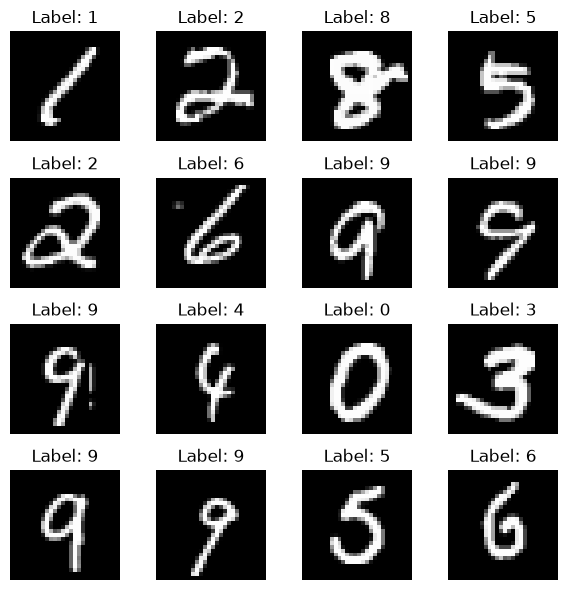

In [4]:
# visualize a batch of images 

# Grab one batch from the DataLoader
images, labels = next(iter(train_loader))

# Visualize using our utility function
show_batch(images, labels, n=16)


Each image above is a 28×28 grayscale digit from MNIST.  
Notice that the background is now dark and the digit strokes are light — this is due to our `[-1, 1]` normalization.

In the next stages:
- The **Generator** will try to create similar images from random noise and class labels.
- The **Discriminator** (and later, our **Diffusion Model**) will try to distinguish real from synthetic handwriting.

For now, let’s save a small batch of these processed images — we’ll reuse them to verify that our models are conditioning correctly.

In [5]:
# Save processed samples
os.makedirs("../data/processed", exist_ok=True)

sample_batch = {
    "images": images[:100].to(device),
    "labels": labels[:100].to(device)
}

torch.save(sample_batch, "../data/processed/sample_batch.pt")
print("Saved 100 sample images to /data/processed/sample_batch.pt")

Saved 100 sample images to /data/processed/sample_batch.pt


In [6]:
# Dataset statistics
train_dataset = train_loader.dataset
all_labels = train_dataset.targets
class_counts = torch.bincount(all_labels, minlength=10)

print(f"Total training samples: {len(train_dataset)}")
print(f"Total test samples:     {len(test_loader.dataset)}")
print("Class distribution (train):")
for digit, count in enumerate(class_counts.tolist()):
    print(f"  digit {digit}: {count:5d} images ({count / len(train_dataset):.2%})")


Total training samples: 60000
Total test samples:     10000
Class distribution (train):
  digit 0:  5923 images (9.87%)
  digit 1:  6742 images (11.24%)
  digit 2:  5958 images (9.93%)
  digit 3:  6131 images (10.22%)
  digit 4:  5842 images (9.74%)
  digit 5:  5421 images (9.04%)
  digit 6:  5918 images (9.86%)
  digit 7:  6265 images (10.44%)
  digit 8:  5851 images (9.75%)
  digit 9:  5949 images (9.92%)
